In [1]:
# Error analysis, cell 1: BLEU-4 for groups of validation photos, for every model
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from nltk.translate.bleu_score import corpus_bleu
from captioning.clean import load_config
from captioning.evaluate import load_references, nouns, MALE, FEMALE
from captioning.vocab import tokenize

cfg = load_config()
refs = load_references(cfg, "val")
ref_words = {img: {w for cap in caps for w in cap} for img, caps in refs.items()}
FIG_DIR = Path("reports/figures")
SEEDS = (42, 43, 44)

def load_preds(path):
    return dict(pd.read_csv(path).fillna("").values)

constant = json.loads(Path("configs/constant.json").read_text())["caption"]
models = {"Constant caption": {img: constant for img in refs},
          "Nearest neighbour": load_preds("results/knn_val_predictions.csv")}
deep = {s: load_preds(f"results/predictions_simple_deep_squash_d0.3_s{s}.csv") for s in SEEDS}

DOG = {"dog", "dogs", "puppy"}
groups = {
    "All photos": lambda w: True,
    "Dog mentioned": lambda w: bool(DOG & w),
    "No dog": lambda w: not (DOG & w),
    "'Man' mentioned": lambda w: "man" in w,
    "No 'man'": lambda w: "man" not in w,
    "Male words only": lambda w: bool(MALE & w) and not (FEMALE & w),
    "Female words only": lambda w: bool(FEMALE & w) and not (MALE & w),
}

def bleu4(preds, images):
    return corpus_bleu([refs[i] for i in images], [tokenize(preds[i]) for i in images]) * 100

rows = []
for group, keep in groups.items():
    images = [i for i in sorted(refs) if keep(ref_words[i])]
    row = {"Group": group, "Photos": len(images)}
    for name, preds in models.items():
        row[name] = f"{bleu4(preds, images):.2f}"
    deep_scores = [bleu4(deep[s], images) for s in SEEDS]
    row["Simple deep (3 seeds)"] = f"{np.mean(deep_scores):.2f} ± {np.std(deep_scores, ddof=1):.2f}"
    rows.append(row)

group_table = pd.DataFrame(rows)
print(group_table.to_string(index=False))
group_table.to_csv("results/group_bleu4.csv", index=False)

            Group  Photos Constant caption Nearest neighbour Simple deep (3 seeds)
       All photos    1000             5.10              5.16           5.88 ± 0.49
    Dog mentioned     244            15.38              6.66           5.05 ± 2.50
           No dog     756             0.62              4.62           6.10 ± 0.61
  'Man' mentioned     297             1.03              5.80          10.69 ± 0.74
         No 'man'     703             6.49              4.88           3.23 ± 0.95
  Male words only     413             3.02              3.75           7.63 ± 0.27
Female words only     194             1.19              4.60           3.81 ± 1.31


In [2]:
# Error analysis, cell 2: sort errors into kinds and count them
ref_nouns = {}
for img, caps in refs.items():
    counts = {}
    for cap in caps:
        for n in nouns(cap):
            counts[n] = counts.get(n, 0) + 1
    ref_nouns[img] = max(counts, key=counts.get) if counts else None   # main subject

def error_kinds(preds):
    most_common = pd.Series(list(preds.values())).value_counts().index[0]
    k = {"Same sentence as its most common caption": 0,
         "Says 'man', no human did": 0,
         "Says 'dog', no human did": 0,
         "Gender word no human used": 0,
         "Misses the main subject": 0}
    for img in sorted(refs):
        hyp = set(tokenize(preds[img]))
        words = ref_words[img]
        k["Same sentence as its most common caption"] += preds[img] == most_common
        k["Says 'man', no human did"] += "man" in hyp and "man" not in words
        k["Says 'dog', no human did"] += "dog" in hyp and "dog" not in words
        k["Gender word no human used"] += bool((MALE & hyp and not MALE & words) or
                                               (FEMALE & hyp and not FEMALE & words))
        k["Misses the main subject"] += ref_nouns[img] is not None and ref_nouns[img] not in hyp
    return k

knn_kinds = error_kinds(models["Nearest neighbour"])
deep_kinds = [error_kinds(deep[s]) for s in SEEDS]
kinds_table = pd.DataFrame({
    "Error kind (of 1,000 photos)": list(knn_kinds),
    "Nearest neighbour": list(knn_kinds.values()),
    "Simple deep (3 seeds)": [f"{np.mean([d[k] for d in deep_kinds]):.0f} ± "
                              f"{np.std([d[k] for d in deep_kinds], ddof=1):.0f}" for k in knn_kinds],
})
print(kinds_table.to_string(index=False))
kinds_table.to_csv("results/error_kinds.csv", index=False)

print("\nMost common main subjects the deep model (seed 42) misses:")
missed = pd.Series([ref_nouns[i] for i in refs
                    if ref_nouns[i] and ref_nouns[i] not in set(tokenize(deep[42][i]))])
print(missed.value_counts().head(8).to_string())

            Error kind (of 1,000 photos)  Nearest neighbour Simple deep (3 seeds)
Same sentence as its most common caption                 14             770 ± 398
                Says 'man', no human did                232              650 ± 92
                Says 'dog', no human did                220             286 ± 425
               Gender word no human used                307              472 ± 23
                 Misses the main subject                831              819 ± 84

Most common main subjects the deep model (seed 42) misses:
dog         93
dogs        41
boy         38
girl        36
people      34
water       23
woman       22
children    21


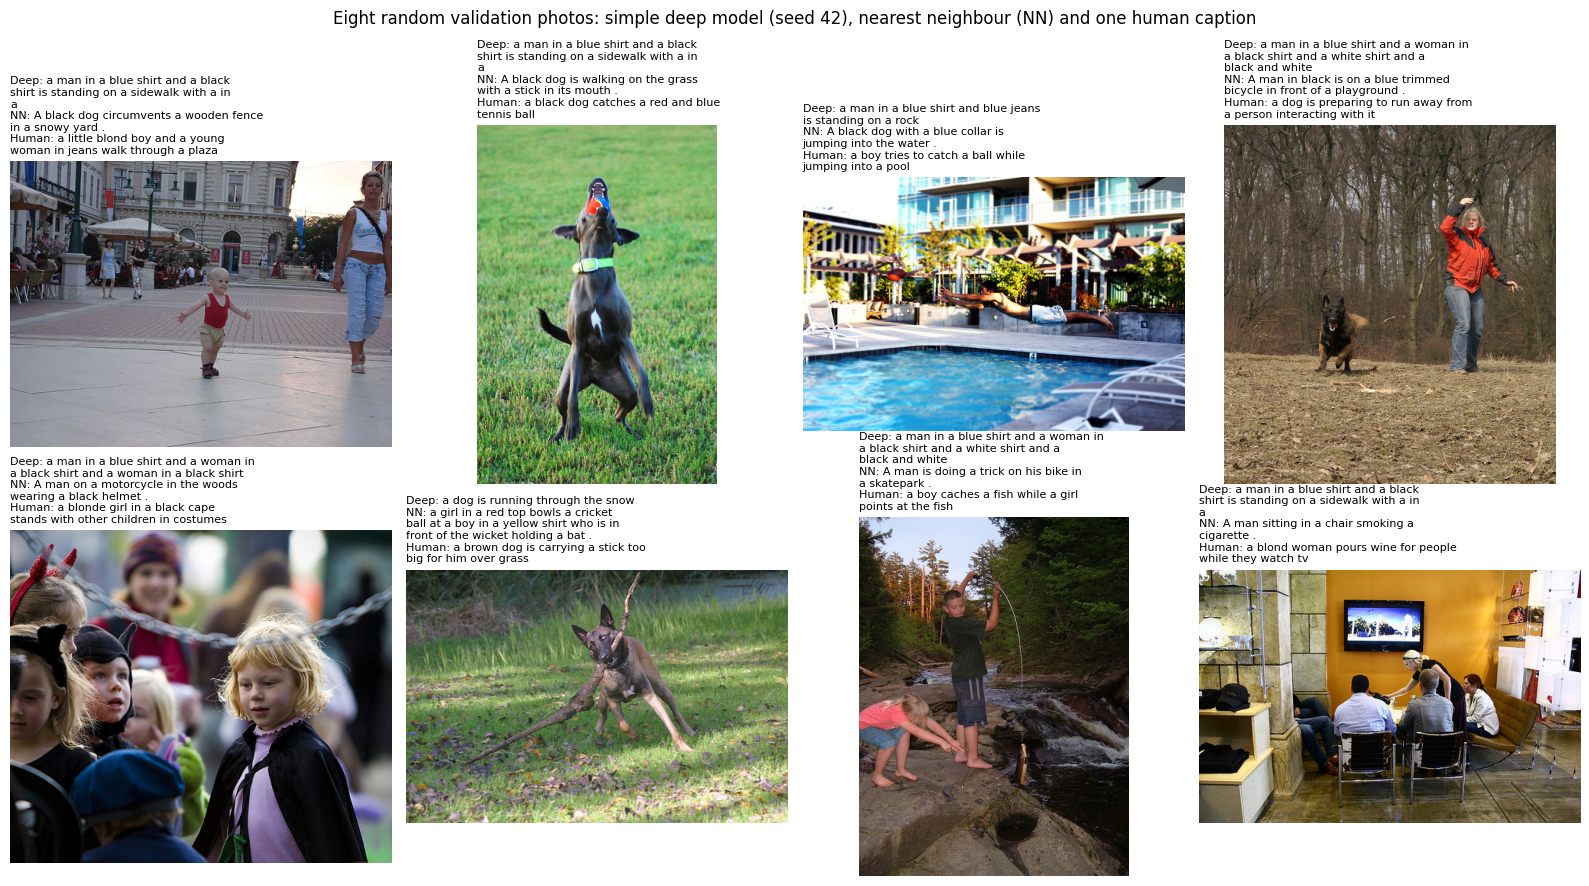

In [3]:
# Error analysis, cell 3: figure of representative errors (8 random validation photos)
rng = np.random.default_rng(cfg["seed"])
picked = rng.choice(sorted(refs), size=8, replace=False)
image_dir = Path(cfg["paths"]["raw_images"])

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, img in zip(axes.flat, picked):
    with Image.open(image_dir / img) as photo:
        ax.imshow(photo)
    text = (f"Deep: {deep[42][img]}\n"
            f"NN: {models['Nearest neighbour'][img]}\n"
            f"Human: {' '.join(refs[img][0])}")
    ax.set_title("\n".join(textwrap.fill(line, 42) for line in text.split("\n")),
                 fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle("Eight random validation photos: simple deep model (seed 42), "
             "nearest neighbour (NN) and one human caption", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "m4_fig3_errors.png", dpi=200)
plt.show()